# 1. 시퀀스 데이터 (Sequence Data)
- 시퀀스 데이터(Sequence Data)는 시간적 혹은 순서적 관계가 중요한 데이터를 말합니다. 
- 일반적인 데이터가 순서와 무관하게 독립적으로 다뤄지는 것과 달리, 시퀀스 데이터는 각 요소가 특정 순서에 따라 나열되어 있고 앞뒤 맥락이 의미를 가집니다. 
- 대표적인 예로는 자연어 문장(단어의 순서 중요), 시계열 데이터(주가, 날씨 변화), 음성 신호(시간에 따른 파형), 영상 프레임(연속된 이미지) 등이 있습니다. 
- 따라서 시퀀스 데이터는 단순한 값들의 모음이 아니라, 순서와 맥락이 포함된 정보 구조로 이해하는 것이 핵심입니다.

# 2. RNN (Recurrent Neural Network)
- RNN(Recurrent Neural Network, 순환 신경망)은 시계열 데이터나 연속적인 데이터를 다룰 때 사용되는 인공 신경망으로
- 일반적인 신경망(CNN, MLP 등)이 입력을 한 번 처리하고 끝나는 것과 달리, 과거의 정보를 기억하며 다음 계산에 반영하는 특징이 있습니다. 
- 일반적인 신경망은 현재 입력만 보고 예측하지만, 시계열 데이터나 자연어처럼 이전 정보가 중요한 경우에는 적절하지 않기 때문에 RNN이 필요합니다. 
- RNN은 기존 신경망과 달리 자신의 출력을 다시 입력으로 사용하여 과거 정보를 기억하는 구조를 가지며, 이를 통해 시계열 데이터의 패턴을 학습할 수 있습니다.  
- 그러나 일반적인 RNN은 장기 의존성(Long-Term Dependency) 문제로 인해 학습이 어려울 수 있으며, 
    - 이를 해결하기 위해 장단기 메모리(Long Short-Term Memory, LSTM)나 
    - 게이트 순환 유닛(Gated Recurrent Unit, GRU)과 같은 변형 모델이 개발되었습니다. 

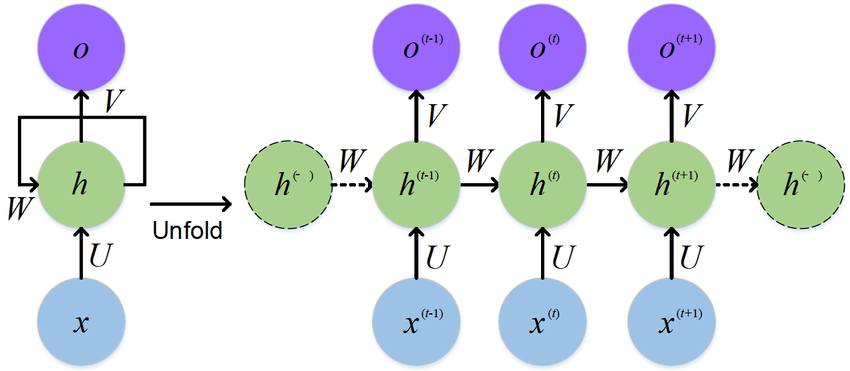 
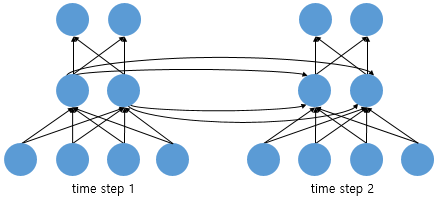

### RNN 구조
```
[batch_size, sequence_length, input_size] # RNN에 들어가는 입력: 3차원 구조
예) [32, 20, 10] # 32개의 시퀀스를 처리하고, 한 시퀀스는 20일이며, 하루마다 10개의 특성이 있음
```

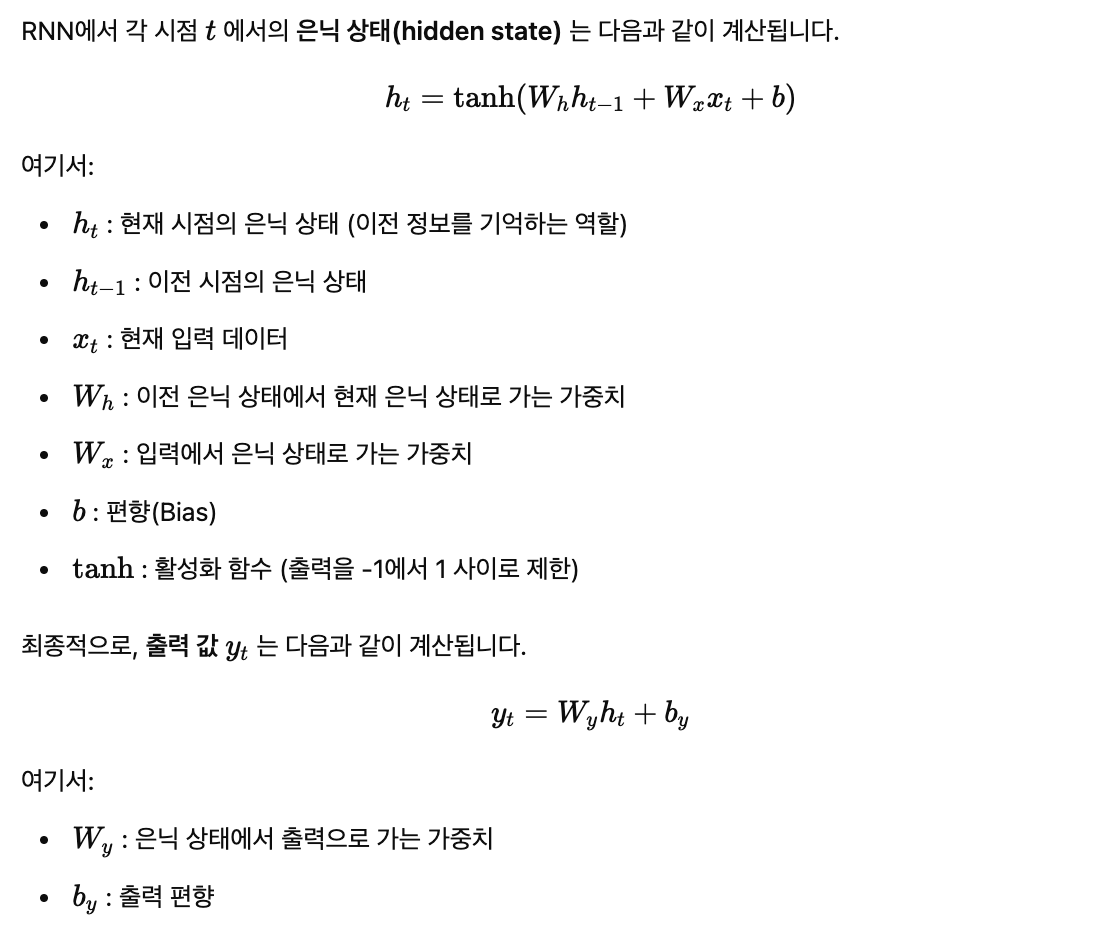

> 이전 시점의 hidden state를 다음 시점으로 계속 넘긴다는 것

# 3. RNN을 이용한 KOSPI 예측

- 20일의 KOSPI 데이터를 넣는다고 가정하면 RNN은 개념적으로 아래처럼 움직임
```
1일차 입력 + 초기 기억 > 1일차 기억
2일차 입력 + 1일차 기억 > 2일차 기억
3일차 입력 + 2일차 기억 > 3일차 기억
...
20일차 입력 + 19일차 기억 > 20일차 기억
```

> 20일차의 최종 hidden state를 Linear Layer에 넣어 다음 날 종가를 예측

### Hidden State
- RNN의 기억(memory)
- 지금까지 들어온 입력에서 다음 계산이 필요하다고 RNN이 학습한 정보를 압축한 벡터
- 예) hidden_size=64라면 각 시점에서 RNN은 64개의 숫자로 이루어진 hidden state를 만듦
    - input_size: 하루에 입력되는 특성 개수
    - sequence_length: 몇일을 볼 것인지
    - hidden_size = RNN 내부에서 정보를 몇 개의 숫자로 표현할 것인지

### tanh(하이퍼볼릭 탄젠트)를 사용하는 이유 
- 입력값을 -1 ~ 1사이로 변환
- RNN에서는 이전 hidden state가 다음 시점 계산에 계속 재사용되기 때문에 값이 지나치게 커지는것을 억제하는 데 도움을 줌
- 시퀀스가 길어지면 tanh와 반복적인 행렬 곱 때문에 기울기 소실 문제가 발생할 수 있음

### RNN의 한계
- RNN은 가까운 과거 정보는 비교적 잘 사용할 수 있음. 매우 오래 전 정보까지 안정적으로 기억하기 어려움
- 긴 시퀀스에서는 LSTM, GRU, Transformer 계열 모델이 많이 사용됨
- 기본 RNN은 순환 신경망의 hidden state와 시계열 입력 구조를 이해하기에 매우 좋은 출발점

In [4]:
import copy
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [5]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


In [6]:
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [7]:
df = pd.read_csv("./data/kospi.csv")
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,04/01/2000,1028.329956,1066.180054,1016.590027,1059.040039,1059.040039,19589800.0
1,05/01/2000,1006.869995,1026.520020,984.049988,986.309998,986.309998,25769600.0
2,06/01/2000,1013.950012,1014.900024,953.500000,960.789978,960.789978,20352300.0
3,07/01/2000,949.169983,970.159973,930.840027,948.650024,948.650024,21566400.0
4,10/01/2000,979.669983,994.940002,974.820007,987.239990,987.239990,24017500.0
...,...,...,...,...,...,...,...
4508,16/01/2018,2504.159912,2524.550049,2498.550049,2521.739990,2521.739990,341600.0
4509,17/01/2018,2517.189941,2521.969971,2506.489990,2515.429932,2515.429932,336700.0
4510,18/01/2018,2527.669922,2532.080078,2512.689941,2515.810059,2515.810059,333100.0
4511,19/01/2018,2519.669922,2524.330078,2513.090088,2520.260010,2520.260010,351800.0


In [8]:
df["Date"] = pd.to_datetime(df['Date'], dayfirst=True, errors="coerce")
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,2000-01-04,1028.329956,1066.180054,1016.590027,1059.040039,1059.040039,19589800.0
1,2000-01-05,1006.869995,1026.520020,984.049988,986.309998,986.309998,25769600.0
2,2000-01-06,1013.950012,1014.900024,953.500000,960.789978,960.789978,20352300.0
3,2000-01-07,949.169983,970.159973,930.840027,948.650024,948.650024,21566400.0
4,2000-01-10,979.669983,994.940002,974.820007,987.239990,987.239990,24017500.0
...,...,...,...,...,...,...,...
4508,2018-01-16,2504.159912,2524.550049,2498.550049,2521.739990,2521.739990,341600.0
4509,2018-01-17,2517.189941,2521.969971,2506.489990,2515.429932,2515.429932,336700.0
4510,2018-01-18,2527.669922,2532.080078,2512.689941,2515.810059,2515.810059,333100.0
4511,2018-01-19,2519.669922,2524.330078,2513.090088,2520.260010,2520.260010,351800.0


In [9]:
numeric_cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")  # 문자를 숫자로 바꿀 수 없다면 에러 발생 대신 NaN으로 채우기

In [10]:
required_cols = ["Date", "Open", "High", "Low", "Close"]
missing_cols = [ col for col in required_cols if col not in df.columns ]
missing_cols

[]

In [11]:
df = df.dropna(subset=required_cols).copy()

In [12]:
# Date column 기준으로 sort
# dropna로 빈 index가 있을 수도 있음
df = df.sort_values("Date").reset_index(drop=True)  # 기존 index 지우고 sort후 새로운 index 사용
print('데이터 기간: ', df["Date"].min(), " ~ ", df['Date'].max())
print('전체 행 수: ', len(df))
df.head()

데이터 기간:  2000-01-04 00:00:00  ~  2018-01-22 00:00:00
전체 행 수:  4452


,Date,Open,High,Low,Close,Adj Close,Volume
0,2000-01-04,1028.329956,1066.180054,1016.590027,1059.040039,1059.040039,19589800.0
1,2000-01-05,1006.869995,1026.520020,984.049988,986.309998,986.309998,25769600.0
2,2000-01-06,1013.950012,1014.900024,953.500000,960.789978,960.789978,20352300.0
3,2000-01-07,949.169983,970.159973,930.840027,948.650024,948.650024,21566400.0
4,2000-01-10,979.669983,994.940002,974.820007,987.239990,987.239990,24017500.0


### 데이터 확인
- 시계열에서는 날짜 순서가 매우 중요함
- 반드시 날짜 오름차순인지 확인해야 함

<class 'pandas.DataFrame'>
RangeIndex: 4452 entries, 0 to 4451
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       4452 non-null   datetime64[us]
 1   Open       4452 non-null   float64       
 2   High       4452 non-null   float64       
 3   Low        4452 non-null   float64       
 4   Close      4452 non-null   float64       
 5   Adj Close  4452 non-null   float64       
 6   Volume     4452 non-null   float64       
dtypes: datetime64[us](1), float64(6)
memory usage: 243.6 KB
None

결측치 개수
Open     0
High     0
Low      0
Close    0
dtype: int64


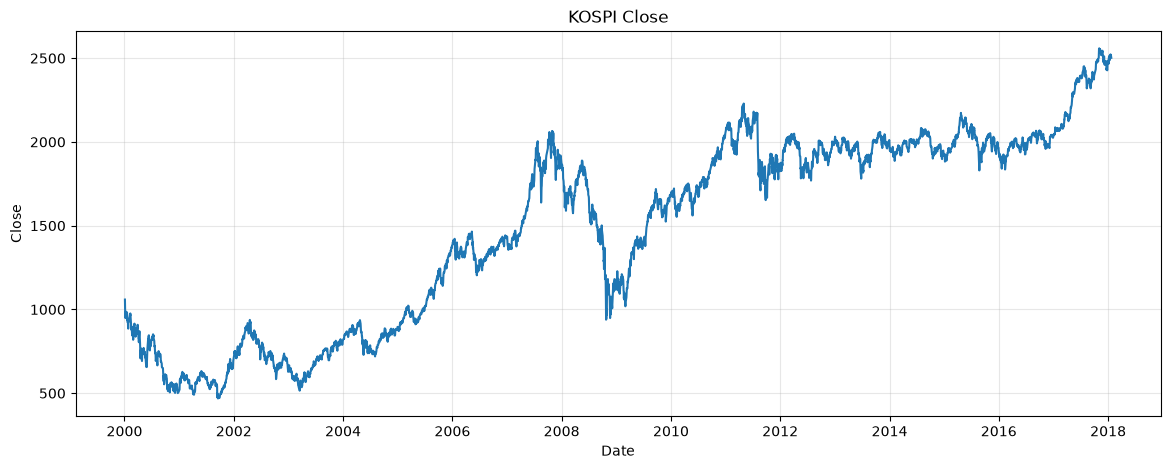

In [13]:
print(df.info())
print()
print("결측치 개수")
print(df[["Open", "High", "Low", "Close"]].isna().sum())

plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Close"])
plt.title("KOSPI Close")
plt.xlabel("Date")
plt.ylabel("Close")
plt.grid(alpha=0.3)
plt.show()

### Feature Engineering
- 사용하는 특성
    - Open, High, Low, Close
    - Return_1d: 전일 대비 종가 수익률
    - Range_pct: 하루 고가-저가 범위
    - OC_pct: 시가 대비 종가 변환율
    - MA5_ratio: 종가 / 5일 이동평균
    - MA20_ratio: 종가 / 20일 이동평균
    - Volatility_10: 최근 10일 수익률 표준편차

목표값은 다음 거래일의 종가 (예측)
```
현재 날짜가 t이면
입력: t일까지의 정보 > 정답: t+1일의 Close
```


In [14]:
# 특성을 추가하기 위해 원본 데이터프레임을 복사
data = df.copy()

# 전일 종가 대비 오늘 종가의 수익률을 계산
data["Return_1d"] = data["Close"].pct_change()

# 오늘의 고가와 저가 차이를 종가로 나눠 하루 가격 변동 폭을 계산
data["Range_pct"] = (data["High"] - data["Low"]) / data["Close"]

# 시가 대비 종가의 변동률을 계산
data["OC_pct"] = (data["Close"] - data["Open"]) / data["Open"]

# 오늘을 포함한 최근 5거래일 종가 평균을 계산
data["MA5"] = data["Close"].rolling(5).mean()

# 오늘을 포함한 최근 20거래일 종가 평균을 계산
data["MA20"] = data["Close"].rolling(20).mean()

# 오늘 종가를 최근 5일 평균과 비교
data["MA5_ratio"] = data["Close"] / data["MA5"]

# 오늘 종가를 최근 20일 평균과 비교
data["MA20_ratio"] = data["Close"] / data["MA20"]

# 최근 10거래일 수익률의 표준편차로 변동성을 계산
data["Volatility_10"] = data["Return_1d"].rolling(10).std()

# 현재 날짜(t)의 입력에 다음 거래일(t+1)의 종가와 날짜를 정답으로 지정
data["Target_Close"] = data["Close"].shift(-1)
data["Target_Date"] = data["Date"].shift(-1)

FEATURES = [
    "Open",             # 해당 거래일의 시가
    "High",             # 해당 거래일의 고가
    "Low",              # 해당 거래일의 저가
    "Close",            # 해당 거래일의 종가
    "Return_1d",        # 전일 대비 종가 수익률
    "Range_pct",        # 하루 고가-저가 변동 폭
    "OC_pct",           # 시가 대비 종가 변동률
    "MA5_ratio",        # 종가와 최근 5일 평균의 비율
    "MA20_ratio",       # 종가와 최근 20일 평균의 비율
    "Volatility_10",    # 최근 10일 수익률의 변동성
]

# rolling으로 생긴 앞부분 NaN과 마지막 target NaN을 제거합니다.
data = data.dropna(subset=FEATURES + ["Target_Close", "Target_Date"]).reset_index(drop=True)

print("사용할 Feature 개수:", len(FEATURES))
print("정제 후 데이터 수:", len(data))

# 날짜, 입력 특성, 정답 날짜와 종가를 확인합니다.
data[["Date"] + FEATURES + ["Target_Date", "Target_Close"]].head()

사용할 Feature 개수: 10
정제 후 데이터 수: 4432


,Date,Open,High,Low,Close,Return_1d,Range_pct,OC_pct,MA5_ratio,MA20_ratio,Volatility_10,Target_Date,Target_Close
0,2000-01-31,924.830017,948.840027,922.919983,943.880005,0.002347,0.027461,0.020598,1.032344,0.990929,0.025395,2000-02-01,928.750000
1,2000-02-01,955.440002,959.309998,923.520020,928.750000,-0.016030,0.038536,-0.027935,1.007524,0.981760,0.025668,2000-02-02,943.590027
2,2000-02-02,929.690002,950.130005,923.400024,943.590027,0.015978,0.028328,0.014951,1.010891,0.999704,0.022495,2000-02-03,950.219971
3,2000-02-03,950.260010,959.000000,934.109985,950.219971,0.007026,0.026194,-0.000042,1.009131,1.007292,0.022477,2000-02-07,973.130005
4,2000-02-07,953.229980,982.030029,951.309998,973.130005,0.024110,0.031568,0.020876,1.026602,1.030241,0.022042,2000-02-08,961.219971


### Train/Val/Test 시간순 분리
- 시계열 데이터에서 가장 중요한 원칙 중 하나는 미래 데이터를 학습에 사용하지 않는 것
- 데이터를 섞지 않고 시간순으로 Train(70%), Val(15%), Test(15%) 로 나눔  
- RANDOM 안됨! Otherwise 데이터 누수 발생 (Data Leakage) 

In [15]:
# 차례대로 데이터 분리

n = len(data)

train_end = int(n * 0.70)  # 70%
val_end = int(n * 0.85)  # 15%

print("Train rows :", train_end)
print("Valid rows :", val_end - train_end)
print("Test rows  :", n - val_end)

print()
print("Train target 기간:",
      data.loc[0, "Target_Date"], "~",
      data.loc[train_end - 1, "Target_Date"])

print("Valid target 기간:",
      data.loc[train_end, "Target_Date"], "~",
      data.loc[val_end - 1, "Target_Date"])

print("Test target 기간 :",
      data.loc[val_end, "Target_Date"], "~",
      data.loc[n - 1, "Target_Date"])

Train rows : 3102
Valid rows : 665
Test rows  : 665

Train target 기간: 2000-02-01 00:00:00 ~ 2012-08-20 00:00:00
Valid target 기간: 2012-08-21 00:00:00 ~ 2015-05-04 00:00:00
Test target 기간 : 2015-05-06 00:00:00 ~ 2018-01-22 00:00:00


### Scaling
- 신경망은 입력 특성들의 숫자 크기가 지나치게 크거나, 피처들이 다르면 학습하기 어려울 수 있음
    - 특성을 비슷한 범위로 변환하면 가중치가 더 균형 있게 조정됨
- Scaler(StandardScaler)의 평균과 표준편차를 계산하는 fit()은 Train 데이터만 수행
- Val/Test 데이터까지 포함해서 fit()하면 나중에 transform 할때 미래 데이터의 통계 정보가 학습 단계에 들어가는 데이터 누수가 될 수 있음

In [16]:
# Scaler 객체 생성
scaler_x = StandardScaler()
scaler_y = StandardScaler()

# fit()은 오직 Train 구간에서만 수행
scaler_x.fit(data.loc[:train_end - 1, FEATURES])
scaler_y.fit(data.loc[:train_end - 1, ["Target_Close"]])

# transform은 같은 scaler로 전체 데이터에 적용
X_all = scaler_x.transform(data[FEATURES]).astype(np.float32)
y_all = scaler_y.transform(data[["Target_Close"]]).astype(np.float32)

print("X_all shape:", X_all.shape)
print("y_all shape:", y_all.shape)

X_all shape: (4432, 10)
y_all shape: (4432, 1)


### 시퀀스 만들기
- 최근 20거래일을 보고 다음 거래일 종가를 예측
- 전체 시계열에서 window를 만든 뒤 정답(target)의 시점에 따라 Train/Val/Test 구분
- 위와 같이 window를 사용해야 Test 시작 첫날을 예측할 때도 바로 앞의 Train/Val 구간 데이터를 과거 정보로 사용할 수 있음

In [17]:
SEQUENCE_LENGTH = 20  # 한 번에 과거 20거래일을 입력으로 사용

def make_sequences(X, y, sequence_length):
    X_seq = []           # 20일치 입력 묶음을 저장
    y_seq = []           # 각 입력 묶음에 대응하는 정답 종가를 저장
    target_indices = []  # 각 샘플이 만들어진 data 행 번호를 저장

    # i = 현재까지 관측한 마지막 행
    # X는 i를 포함한 최근 sequence_length개
    # y[i]는 data[i] 다음 거래일의 종가
    # 0부터 시작하는 인덱스 기준으로, 처음 20일을 확보한 시점부터 반복
    for i in range(sequence_length - 1, len(X)):

        # i를 마지막 날로 하는 20일 구간의 시작 위치
        start = i - sequence_length + 1

        # start부터 i까지의 행을 가져옴. i도 포함되므로 총 20일
        X_seq.append(X[start:i + 1])

        # y[i]는 i번째 행에 저장된 다음 거래일 종가(Target_Close)
        y_seq.append(y[i])

        # 이 샘플의 입력이 끝나는 행 번호를 저장
        target_indices.append(i)

    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.float32),
        np.asarray(target_indices, dtype=np.int64),
    )
# -------------------------------------------------- make_sequences() 끝

# 전체 데이터에서 20일 입력 묶음과 정답을 생성
X_seq, y_seq, target_indices = make_sequences(
    X_all,
    y_all,
    SEQUENCE_LENGTH
)

print("전체 sequence shape:", X_seq.shape)
print("전체 target shape  :", y_seq.shape)
print("target index shape :", target_indices.shape)

전체 sequence shape: (4413, 20, 10)
전체 target shape  : (4413, 1)
target index shape : (4413,)


### 텐서 모양 읽기
```
X_seq.shape이 예를 들어 (6000, 20, 10)
- 6000: 만들어진 시퀀스 개수
- 20: 한 시퀀스에 포함된 거래일 수
- 10: 하루에 들어가는 feature 개수
```

In [18]:
# 구간 마스크 세팅
train_mask = target_indices < train_end
val_mask = (target_indices >= train_end) & (target_indices < val_end)
test_mask = target_indices >= val_end

# 마스크를 배열에 적용 Train 나누기
X_train = X_seq[train_mask]
y_train = y_seq[train_mask]

# Vallidation 나누기
X_val = X_seq[val_mask]
y_val = y_seq[val_mask]

# Test 나누기
X_test = X_seq[test_mask]
y_test = y_seq[test_mask]

# 각 묶음에 해당하는 행 번호를 보관
idx_train = target_indices[train_mask]
idx_val = target_indices[val_mask]
idx_test = target_indices[test_mask]

print("Train:", X_train.shape, y_train.shape)
print("Valid:", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (3083, 20, 10) (3083, 1)
Valid: (665, 20, 10) (665, 1)
Test : (665, 20, 10) (665, 1)


### Dataset과 DataLoader
- RNN은 한 번에 전체 데이터를 넣기보다 mini-batch 단위로 넣음
- 학습 DataLoader의 shuffle=True는 각 시퀀스 내부의 날짜 순서를 섞는 것이 아님
    - 이미 만들어진 20일 짜리 window들의 순서만 배치 구성 단계에서 섞음
    - 각 window 내부의 1일, 2일, ...> 20일 순서는 그대로 유지
- 이번 RNN 모델은 각 window마다 hidden state를 0에서 시작하는 방식이므로 학습 window의 batch 순서를 섞어도 됨

In [19]:
class SequenceDataset(Dataset):
    # X, y를 PyTorch tensor로 저장
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    # 데이터 샘플 개수
    def __len__(self):
        return len(self.X)

    # idx번째 샘플의 입력과 정답을 한 쌍으로 반환
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# 한 번에 최대 64개 샘플을 묶어 처리
BATCH_SIZE = 64

# Train Data
train_loader = DataLoader(
    SequenceDataset(X_train, y_train),  # 학습용 Dataset 생성
    batch_size=BATCH_SIZE,              # DataLoader로 데이터를 64개씩 꺼냄
    shuffle=True  # 묶여져있는 64개 학습 샘플(20일씩)을 꺼내는 순서 섞기 >> 일반화 성능 높이기 위함 (순서 편향 줄이기)
)

# Validation Data
val_loader = DataLoader(
    SequenceDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False  # 검증 테스트 샘플 순서 유지
)

# Test Data
test_loader = DataLoader(
    SequenceDataset(X_test, y_test),
    batch_size=BATCH_SIZE,
    shuffle=False
)

# train_loaderdptj 첫 번째 학습 배치 꺼내기
# xb: 배치에 들어 있는 input 시퀀스들
# yb: 그 input에 대응하는 정답 종가들
xb, yb = next(iter(train_loader))

print("한 배치 X:", xb.shape)
print("한 배치 y:", yb.shape)

한 배치 X: torch.Size([64, 20, 10])
한 배치 y: torch.Size([64, 1])


### PyTorch RNN 모델 (기존 만들어져있는 모델)
- nn.RNN(..., batch_first=True)에 입력되는 텐서는 [batch, sequence_length, input_size] 형태
- 출력: out = [batch, sequence_length, hidden_state] 
- 출력에서 모든 시점 중 마지막 시점의 hidden_state는 out[:, -1, :]만 가져와 Linear Layer에 넣어 다음날 종가 한 개를 예측할 수 있음
- 회귀 문제의 출력값은 0~1로 제한할 필요가 없으므로 마지막 층은 Linear 출력 (logit값) 그대로 사용

In [20]:
# PyTorch 신경망의 기본 클래스인 nn.Module을 상속해 새 모델을 만든다.
class RNNRegressor(nn.Module):
    def __init__(
        self,
        input_size,     # 하루 입력 feature 개수
        hidden_size=64, # RNN이 각 날짜의 정보를 표현하는 hidden_state 크기
        num_layers=2,   # RNN 층을 2 겹으로 쌓기
        dropout=0.10    # 층 사이에서 일부 값을 무작위로 끄는 비율 (과적합 줄이기 위함)
    ):
        super().__init__()  # PyTorch 모델의 기본 초기화 작업 수행

        # RNN 층 세팅 (입력 시퀀스를 순서대로 처리함)
        self.rnn = nn.RNN(
            input_size=input_size,      # 하루에 특성 10개 받음 (layer1에만 적용 >> layer2부터 64개 hidden_state로 바뀌어 입력됨)
            hidden_size=hidden_size,    # 각 시점의 hidden_state 크기 64
            num_layers=num_layers,      # RNN 층은 2개
            nonlinearity="tanh",        # RNN의 비선형 함수: tanh
            batch_first=True,           # 입력 모양 [batch_size, seq_length, feature_size]
            dropout=dropout if num_layers > 1 else 0.0,  # layer가 2개 이상이면 층 사이에 dropout 적용 (학습에만 적용)
        )

        # 출력층
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # 초기 hidden state를 직접 주지 않으면 PyTorch가 0으로 초기화합니다.
        # out: 마지막 층(Layer 2)이 1일차~20일차에 만든 기억을 모두 모은 것
        # h_n: 각 층(Layer 1, Layer 2)이 20일차에 만든 마지막 기억을 모은 것
        # 단방향 RNN에서는 [num_layers, batch, hidden] 형태
        out, h_n = self.rnn(x)

        # out shape:
        # [batch, sequence_length, hidden_size]
        last_hidden = out[:, -1, :] # h_n[-1]

        pred = self.fc(last_hidden)
        return pred

# 모델 생성
model = RNNRegressor(
    input_size=len(FEATURES),
    hidden_size=64,
    num_layers=2,
    dropout=0.10
).to(DEVICE)

print(model)

RNNRegressor(
  (rnn): RNN(10, 64, num_layers=2, batch_first=True, dropout=0.1)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [21]:
# 텐서 모양 직접 확인
model.eval()

with torch.no_grad():
    sample_x = xb[:4].to(DEVICE)

    out, h_n = model.rnn(sample_x)

print("입력 sample_x :", sample_x.shape)
print("RNN out       :", out.shape)
print("RNN h_n       :", h_n.shape)
print("마지막 시점    :", out[:, -1, :].shape)

입력 sample_x : torch.Size([4, 20, 10])
RNN out       : torch.Size([4, 20, 64])
RNN h_n       : torch.Size([2, 4, 64])
마지막 시점    : torch.Size([4, 64])


### Loss와 Optimizer
- HuberLoss
    - 주가 데이터에는 급등/급락처럼 큰 오차가 발생할 수 있음
    - HuberLoss는 작은 오차에서는 MSE처럼 부드럽게 동작하고, 큰 오차에서는 MSE보다 이상치의 영향을 덜 크게 받음

In [22]:
# 예측값과 정답의 오차를 계산하는 손실 함수
criterion = nn.HuberLoss(delta=1.0)  

# 가중치를 수정하는 담당
optimizer = torch.optim.AdamW(  # AdamW: 각 파라미터의 기울기 정보를 이용해 수정량을 조절
    model.parameters(),  # 학습 중 업데이트할 모델의 가중치와 편향
    lr=1e-3,             # 학습률: 가중치를 얼마나 크게 조정할지
    weight_decay=1e-4    # 가중치가 지나치게 커지는 것은 억제하는 규제값
)

# 검증 손실 개선을 멈추면 학습률 낮춤
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",  # 검증 손실이 낮아지는 것을 개선으로 판단
    factor=0.5,  # 개선이 없으면 학습률을 현재 값의 절반으로 줄임
    patience=5   # 5번의 평가 동안 개선이 없으면 다음 평가에서 학습률 감소
)

MAX_EPOCHS = 200   # 학습을 최대 200회 반복 (epoch마다 전체 학습 데이터를 한 번 사용)
PATIENCE = 15      # 보통 검증 성능이 15회 개선되지 않으면 조기 종료할 때 사용
CLIP_NORM = 1.0    # 기울기(gradient)의 크기가 커지지 않도록 최대 norm을 제한

In [23]:
# 가중치를 바꾸지 않고 성능 확인
def evaluate_loss(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_count = 0

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)  # xb: 입력인 20일치 데이터 묶음
            yb = yb.to(device)  # yb: 각 입력에 대응하는 다음 거래일 종가 정답

            # 예측한 뒤 정답과 비교
            pred = model(xb)  # RNN과 Linear 층을 모두 실행
            loss = criterion(pred, yb)

            batch_size = xb.size(0)  # 현재 배치의 샘플 수
            total_loss += loss.item() * batch_size
            total_count += batch_size

    # 전체 샘플의 평균 손실 반환 (가중치 변경 X)
    return total_loss / total_count 

# -----------------------------------------------------------------------------
# 가장 성능 좋은 모델 저장준비 
best_val_loss = float("inf")  # 지금까지 가장 낮았던 검증 손실 (초기화를 무한대로 설정)
best_state = None             # 가장 좋았던 모델의 가중치 등을 보관
wait = 0                      # 검증 손실이 연속으로 개선되지 않은 횟수

# epoch마다 학습/검증 손실 기록 (시각화 목적)
train_history = []  
val_history = []

# -----------------------------------------------------------------------------
# epoch마다 학습 시작
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()  # 매번 학습 모드로 바꿔 dropout 켜기 (앞선 evaluate_loss에서 model.eval() 호출 했으므로 다음 학습 전에 다시 model.train()으로 변경)

    # 이번 epoch의 손실 합계 & 샘플 수 0으로 초기화
    train_loss_sum = 0.0    
    train_count = 0         

    # 배치마다 실제 학습 수행
    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        # 기울기 비우기 (이전 배치의 기울기가 이번 배치의 기울기에 더해지는 것을 막기 위함)
        optimizer.zero_grad(set_to_none=True)

        # 현재 가중치로 예측하고 오차를 계산
        pred = model(xb)
        loss = criterion(pred, yb)

        # 가중치 어떻게 바꿀지 기울기 계산
        loss.backward()

        # 모든 가중치 대상으로 폭주하는것 방지
        torch.nn.utils.clip_grad_norm_(  # inplace 함수 (위에 _붙임)
            model.parameters(),
            max_norm=CLIP_NORM
        )  # 기울기가 너무 크면 줄임

        # 기울기를 바탕으로 가중치와 편향 수정
        optimizer.step()  # RNN과 Linear층의 가중치/편향 모두 수정 대상

        # 이번 Batch의 손실과 샘플 수를 누적
        batch_size = xb.size(0)
        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

# -----------------------------------------------------------------------------
# 한 epoch가 끝나면 검증

    # 이번 epoch 동안 기록한 학습 손실의 평균
    train_loss = train_loss_sum / train_count

    # 이번 epoch의 학습이 끝난 모델로 검증 손실 계산
    # 검증 데이터로는 가중치 수정 X
    val_loss = evaluate_loss(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    # 손실 기록 
    train_history.append(train_loss)
    val_history.append(val_loss)

    # 손실의 개선이 멈추면 scheduler가 학습률 줄임
    scheduler.step(val_loss)

    # 기존 최고 기록보다 검증 손실이 낮아졌는지 확인
    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss                        # 개선됐다면 최고 기록 저장
        best_state = copy.deepcopy(model.state_dict())  # 검증 성능이 가장 좋았던 순간의 모델 상태를 저장 (학습으로 조정된 값들을 복사해서 보관)
        wait = 0   # 개선됐다면 기다린 횟수를 0으로 초기화
    else:
        wait += 1  # 개선되지 않았다면 기다린 횟수 1누적

    # 첫 epoch, 10, 20, 30, ... epoch 결과 출력
    if epoch == 1 or epoch % 10 == 0:
        lr = optimizer.param_groups[0]["lr"]    # 현재 학습률 저장
        print(
            f"Epoch {epoch:03d} | "
            f"Train {train_loss:.6f} | "
            f"Valid {val_loss:.6f} | "
            f"LR {lr:.2e}"
        )

    # 검증 손실이 15 epoch 연속 개선되지 않을 때 학습 끝내기 (PATIENCE=15)
    if wait >= PATIENCE: 
        print(f"\nEarly Stopping: epoch {epoch}")
        break
# --------------------------------------------------------------------
# 가장 Validation 성능이 좋았던 가중치 복원
if best_state is not None:
    model.load_state_dict(best_state)

print("Best validation loss:", best_val_loss)

Epoch 001 | Train 0.054948 | Valid 0.001291 | LR 1.00e-03
Epoch 010 | Train 0.001638 | Valid 0.000467 | LR 1.00e-03
Epoch 020 | Train 0.001278 | Valid 0.000497 | LR 1.00e-03
Epoch 030 | Train 0.001311 | Valid 0.000437 | LR 5.00e-04
Epoch 040 | Train 0.001135 | Valid 0.000393 | LR 2.50e-04
Epoch 050 | Train 0.001031 | Valid 0.000754 | LR 1.25e-04

Early Stopping: epoch 55
Best validation loss: 0.00039326825005849616


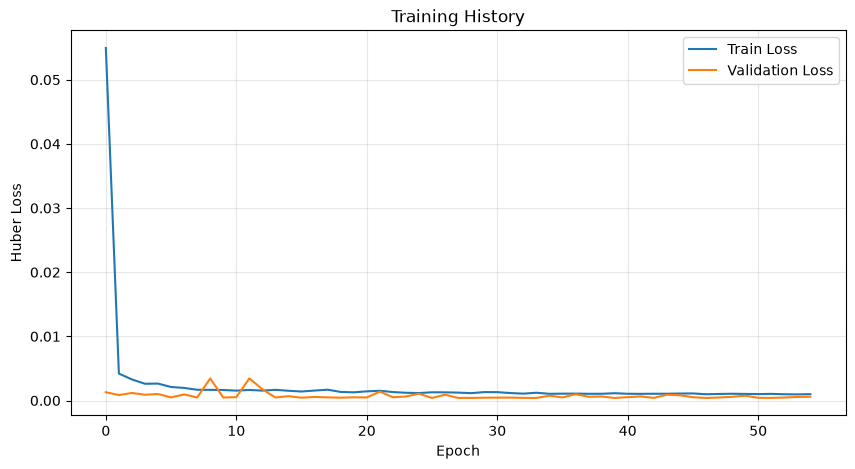

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(train_history, label="Train Loss")
plt.plot(val_history, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.title("Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
def predict(model, loader, device):
    model.eval()  # 추론 모드 (dropout 끄기)

    preds = []
    trues = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)

            pred = model(xb)

            preds.append(pred.cpu().numpy())  # 예측값 모으기
            trues.append(yb.numpy())          # 정답 모으기

    return np.vstack(preds), np.vstack(trues) # 여러 배치의 결과를 하나로 합치기


pred_scaled, true_scaled = predict(
    model,
    test_loader,
    DEVICE
)

# Scale된 값을 원래 종가 단위로 되돌리기
# .ravel()로 배열 모양 변경
pred_close = scaler_y.inverse_transform(pred_scaled).ravel()
true_close = scaler_y.inverse_transform(true_scaled).ravel()

print("예측 개수:", len(pred_close))
print("예측값 앞 5개:", np.round(pred_close[:5], 2))
print("실제값 앞 5개:", np.round(true_close[:5], 2))

예측 개수: 665
예측값 앞 5개: [2119.74 2095.94 2082.73 2078.72 2090.44]
실제값 앞 5개: [2104.58 2091.   2085.52 2097.38 2096.77]


In [28]:
# mape: 실제값 대비 몇 % 정도 틀렸는지를 확인
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)  
    rmse = np.sqrt(mse)                       
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "MAPE(%)": mape,
    }


rnn_metrics = regression_metrics(true_close, pred_close)

for name, value in rnn_metrics.items():
    print(f"{name}: {value:.4f}")

RMSE: 77.3767
MAE: 45.9400
MAPE(%): 1.9596


### Naive Baseline과 비교
- 주가 지수는 인접한 날짜의 가격이 매우 비슷하기 때문에 이런 단순한 RNN 모델도 RMSE가 낮게 나올 수 있음 >> 좋은 모델이라고 판단 하면 안됨

In [29]:
# 각 Test sequence의 마지막 관측일에 해당하는 실제 Close
current_close = data.loc[idx_test, "Close"].to_numpy()

# Naive 예측: 내일 종가 = 오늘 종가
naive_pred = current_close.copy()

naive_metrics = regression_metrics(true_close, naive_pred)

comparison = pd.DataFrame(
    [rnn_metrics, naive_metrics],
    index=["RNN", "Naive Baseline"]
)

comparison

,RMSE,MAE,MAPE(%)
RNN,77.376716,45.940014,1.959580
Naive Baseline,15.299925,11.224154,0.535964


### 상승/하락 방향 정확도
가격 자체를 얼마나 가깝게 맞히는 것과 방향을 맞히는 것은 다른 문제
1. 실제 방향: 내일 실제 종가 - 오늘 종가
2. 예측 방향: 내일 예측 종가 - 오늘 종가

> 부호가 같은지 비교

In [30]:
actual_direction = np.sign(true_close - current_close)
pred_direction = np.sign(pred_close - current_close)
naive_direction = np.sign(naive_pred - current_close)

direction_accuracy = np.mean(actual_direction == pred_direction) * 100
naive_direction_accuracy = np.mean(actual_direction == naive_direction) * 100

print(f"RNN Direction Accuracy : {direction_accuracy:.2f}%")
print(f"Naive Direction Accuracy: {naive_direction_accuracy:.2f}%")

RNN Direction Accuracy : 49.92%
Naive Direction Accuracy: 0.00%


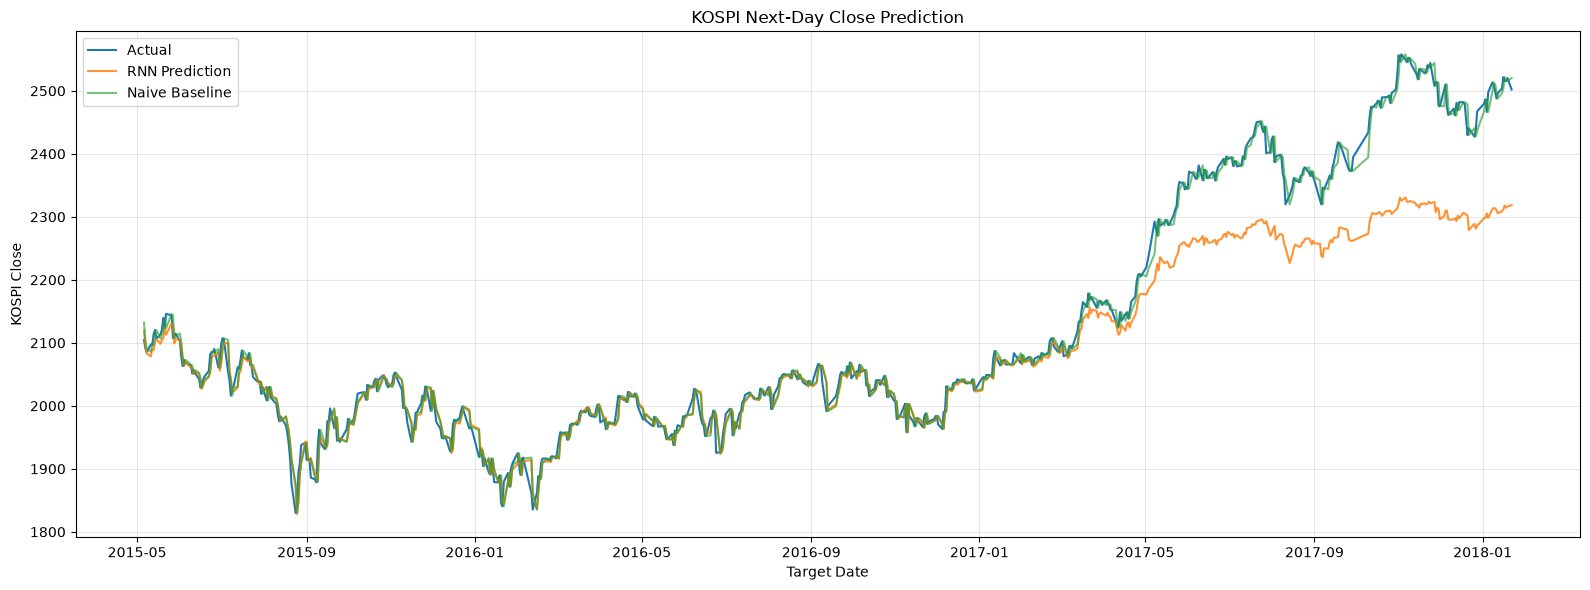

In [31]:
test_dates = pd.to_datetime(
    data.loc[idx_test, "Target_Date"].to_numpy()
)

plt.figure(figsize=(16, 6))
plt.plot(test_dates, true_close, label="Actual")
plt.plot(test_dates, pred_close, label="RNN Prediction", alpha=0.85)
plt.plot(test_dates, naive_pred, label="Naive Baseline", alpha=0.65)

plt.title("KOSPI Next-Day Close Prediction")
plt.xlabel("Target Date")
plt.ylabel("KOSPI Close")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

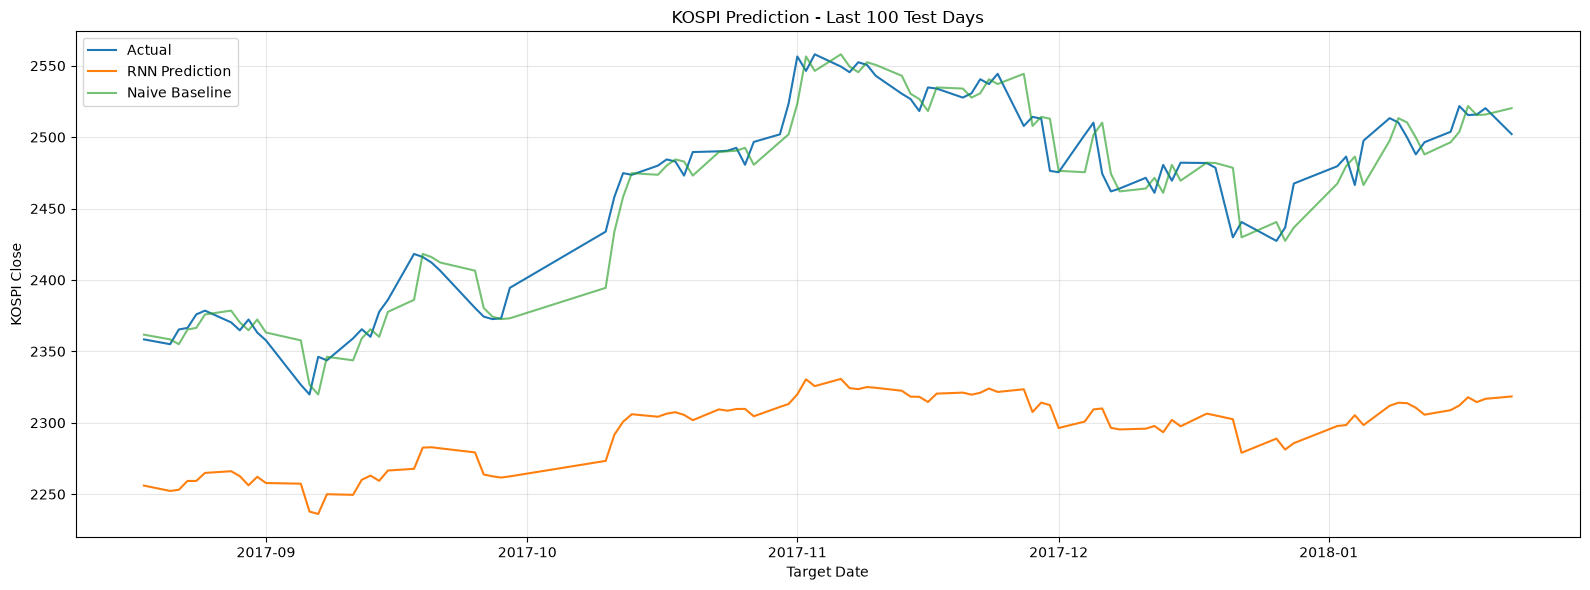

In [32]:
N_VIEW = min(100, len(test_dates))

plt.figure(figsize=(16, 6))

plt.plot(
    test_dates[-N_VIEW:],
    true_close[-N_VIEW:],
    label="Actual"
)

plt.plot(
    test_dates[-N_VIEW:],
    pred_close[-N_VIEW:],
    label="RNN Prediction"
)

plt.plot(
    test_dates[-N_VIEW:],
    naive_pred[-N_VIEW:],
    label="Naive Baseline",
    alpha=0.65
)

plt.title(f"KOSPI Prediction - Last {N_VIEW} Test Days")
plt.xlabel("Target Date")
plt.ylabel("KOSPI Close")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
result_df = pd.DataFrame({
    "Target_Date": test_dates,
    "Current_Close": current_close,
    "Actual_Next_Close": true_close,
    "RNN_Prediction": pred_close,
    "Naive_Prediction": naive_pred,
})

result_df["RNN_Error"] = (
    result_df["Actual_Next_Close"]
    - result_df["RNN_Prediction"]
)

result_df.tail(20)

,Target_Date,Current_Close,Actual_Next_Close,RNN_Prediction,Naive_Prediction,RNN_Error
645,2017-12-21,2478.530029,2429.830078,2302.474121,2478.530029,127.355957
646,2017-12-22,2429.830078,2440.540039,2278.994873,2429.830078,161.545166
647,2017-12-26,2440.540039,2427.340088,2288.906250,2440.540039,138.433838
648,2017-12-27,2427.340088,2436.669922,2281.246094,2427.340088,155.423828
649,2017-12-28,2436.669922,2467.489990,2285.704590,2436.669922,181.785400
650,2018-01-02,2467.489990,2479.649902,2297.752441,2467.489990,181.897461
651,2018-01-03,2479.649902,2486.350098,2298.366211,2479.649902,187.983887
652,2018-01-04,2486.350098,2466.459961,2305.306152,2486.350098,161.153809
653,2018-01-05,2466.459961,2497.520020,2298.380371,2466.459961,199.139648
654,2018-01-08,2497.520020,2513.280273,2311.917480,2497.520020,201.362793
